  Srore_id Product id  YearMonth   Volume
0    DM-01       pd_1     201301   7.6680
1    DM-01       pd_1     201401  14.1432
2    DM-01       pd_1     201501  11.1120
3    DM-01       pd_1     201601  15.3360
4    DM-01       pd_1     201701  15.9885
(60, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Srore_id    60 non-null     object 
 1   Product id  60 non-null     object 
 2   YearMonth   60 non-null     int64  
 3   Volume      60 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 2.0+ KB
None
Srore_id      0
Product id    0
YearMonth     0
Volume        0
dtype: int64


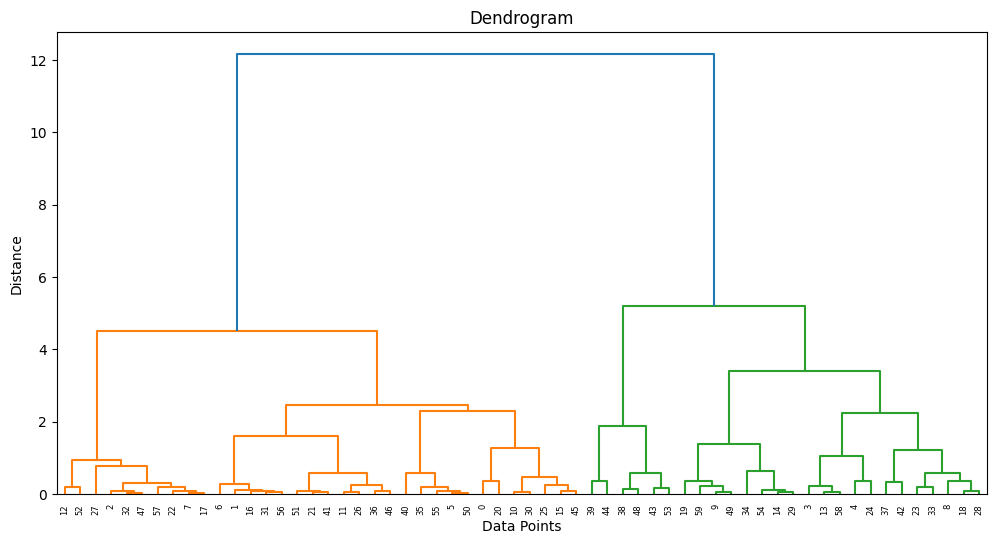

  Srore_id Product id  YearMonth   Volume  Cluster
0    DM-01       pd_1     201301   7.6680        0
1    DM-01       pd_1     201401  14.1432        0
2    DM-01       pd_1     201501  11.1120        0
3    DM-01       pd_1     201601  15.3360        1
4    DM-01       pd_1     201701  15.9885        1
Cluster
0    34
1    20
2     6
Name: count, dtype: int64


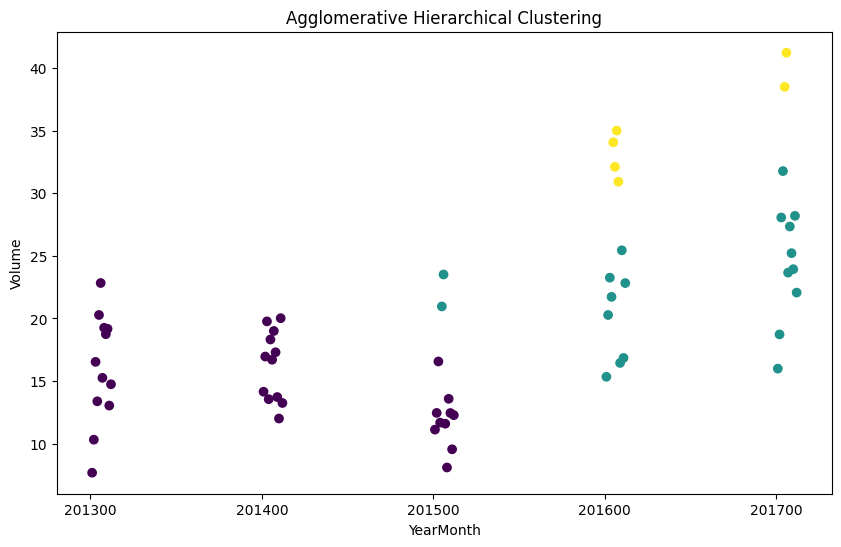

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

df = pd.read_csv("Retail.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())

X = df[["YearMonth", "Volume"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

n_clusters = 3

model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="ward"
)

df["Cluster"] = model.fit_predict(X_scaled)

print(df.head())
print(df["Cluster"].value_counts())

plt.figure(figsize=(10, 6))
plt.scatter(df["YearMonth"], df["Volume"], c=df["Cluster"])
plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("YearMonth")
plt.ylabel("Volume")
plt.show()